Original Dataset:
   Distance  Days Transport  Cost
0       100     1       Bus   500
1       200     2     Train  1200
2       300     2     Train  1500
3       400     3       Bus  2000
4       500     3    Flight  4000
5       600     4    Flight  5000
6       700     4       Bus  3000
7       800     5     Train  3500

Missing Values:
Distance     0
Days         0
Transport    0
Cost         0
dtype: int64

Model Evaluation:
Mean Absolute Error: 236.36
R2 Score: 0.97

Travel Cost Prediction:
Predicted Travel Cost: 2102.27


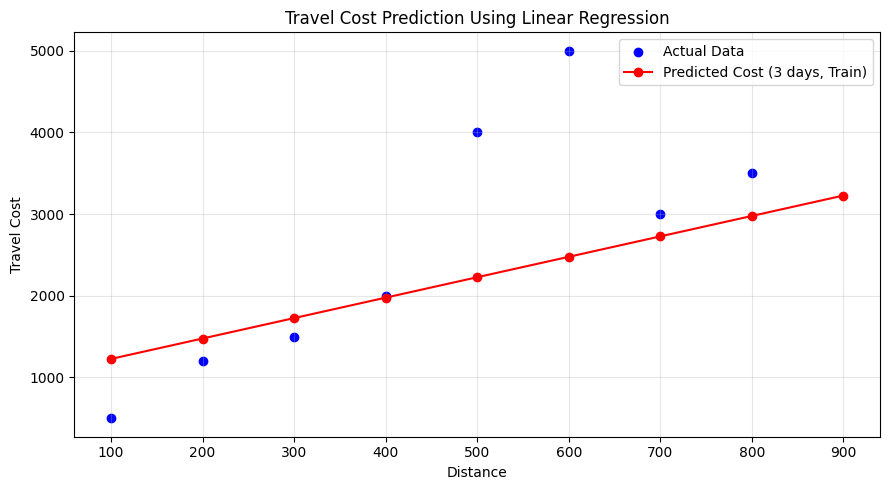

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Create the dataset
data = {
    'Distance': [100, 200, 300, 400, 500, 600, 700, 800],
    'Days': [1, 2, 2, 3, 3, 4, 4, 5],
    'Transport': [
        'Bus', 'Train', 'Train', 'Bus',
        'Flight', 'Flight', 'Bus', 'Train'
    ],
    'Cost': [500, 1200, 1500, 2000, 4000, 5000, 3000, 3500]
}

df = pd.DataFrame(data)

# Display and check the dataset
print("Original Dataset:")
print(df)

print("\nMissing Values:")
print(df.isnull().sum())

# Handle missing values
df = df.dropna().copy()

# Convert transport categories into numeric columns
df = pd.get_dummies(
    df, columns=['Transport'], dtype=int
)

# Select input features and target
X = df[
    ['Distance', 'Days',
     'Transport_Bus', 'Transport_Flight',
     'Transport_Train']
]

Y = df['Cost']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.25, random_state=42
)

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Evaluate the model
predictions = model.predict(X_test)

print("\nModel Evaluation:")
print("Mean Absolute Error:",
      round(mean_absolute_error(y_test, predictions), 2))

print("R2 Score:",
      round(r2_score(y_test, predictions), 2))

# Predict the cost of a new trip
# Example: 450 distance units, 3 days, Train
new_data = pd.DataFrame(
    [[450, 3, 0, 0, 1]],
    columns=[
        'Distance', 'Days',
        'Transport_Bus', 'Transport_Flight',
        'Transport_Train'
    ]
)

predicted_cost = model.predict(new_data)

print("\nTravel Cost Prediction:")
print(f"Predicted Travel Cost: {predicted_cost[0]:.2f}")

# Plot actual data
plt.figure(figsize=(9, 5))

plt.scatter(
    df['Distance'], df['Cost'],
    color='blue', label='Actual Data'
)

# Predict costs while keeping other features fixed
distances = pd.DataFrame({
    'Distance': range(100, 901, 100),
    'Days': [3] * 9,
    'Transport_Bus': [0] * 9,
    'Transport_Flight': [0] * 9,
    'Transport_Train': [1] * 9
})

predicted_costs = model.predict(distances)

# Plot predicted costs
plt.plot(
    distances['Distance'],
    predicted_costs,
    color='red',
    marker='o',
    label='Predicted Cost (3 days, Train)'
)

plt.xlabel("Distance")
plt.ylabel("Travel Cost")
plt.title("Travel Cost Prediction Using Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
